<a href="https://colab.research.google.com/github/silveradium/EN4554-Assignment2/blob/main/220420J_a02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 Assignment 2: CNNs

**Name:** Nawarathne M.A.A.K
**Index number:** 220420J
**GitHub:** https://github.com/silveradium/EN4554-Assignment2

**AI tool use:** Claude was used to help write and explain parts of the code. I have gone through all the code and understand how it works.

**Reference:** LO6 Backpropagation, LO5 Regularization and Optimization

## 0. Setup


In [1]:
import math, time, random
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 0.1 Loading CIFAR-10


Note: Moves everything to the device once, so training does not need a DataLoader. For an MLP the whole dataset fits in memory (about 550 MB as float32), so this is much faster than loading batches from disk.

In [2]:
train_full = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)
classes = train_full.classes

# (50000, 32, 32, 3) uint8  ->  (50000, 3, 32, 32) float in [0, 1]
X_all = torch.tensor(train_full.data).permute(0, 3, 1, 2).float() / 255.0
y_all = torch.tensor(train_full.targets)

# Fixed 45k / 5k split
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_all), generator=g)
train_idx, val_idx = perm[:45000], perm[45000:]
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val,   y_val   = X_all[val_idx],   y_all[val_idx]

# Per channel statistics from the TRAINING split only
mean = X_train.mean(dim=(0, 2, 3))
std  = X_train.std(dim=(0, 2, 3))
X_train = (X_train - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)
X_val   = (X_val   - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)

# Flattened versions for the MLP: each image becomes a 3072 long vector
X_train_flat = X_train.reshape(len(X_train), -1).to(device)
X_val_flat   = X_val.reshape(len(X_val), -1).to(device)
y_train, y_val = y_train.to(device), y_val.to(device)

print("Train:", tuple(X_train_flat.shape), " Val:", tuple(X_val_flat.shape))
print("Channel mean:", mean.numpy().round(4), " Channel std:", std.numpy().round(4))
print("Images per class in validation:", torch.bincount(y_val.cpu()).tolist())

100%|██████████| 170M/170M [32:27<00:00, 87.6kB/s]


Train: (45000, 3072)  Val: (5000, 3072)
Channel mean: [0.4917 0.4823 0.4467]  Channel std: [0.2471 0.2435 0.2616]
Images per class in validation: [488, 512, 532, 471, 471, 514, 507, 500, 504, 501]


# Task 1: Backpropagation

## 1(a) Layers with explicit forward and backward

Note: I have combined the **add** and **mulitply** as a linear function.

Below, $N$ is the batch size. Every input is a row, so $X$ is $N \times D_{in}$.

### Linear layer
Forward: $Y = XW + b$, where $W$ is $D_{in} \times D_{out}$ and $b$ has length $D_{out}$.

Backward, given the upstream gradient $G = \frac{\partial L}{\partial Y}$ (size $N \times D_{out}$),

$$\frac{\partial L}{\partial X} = G W^T, \qquad \frac{\partial L}{\partial W} = X^T G, \qquad \frac{\partial L}{\partial b} = \sum_{n} G_{n,:}$$


$X^T G$ adds up the contribution of every sample in the batch, because all samples share the same $W$. The bias gradient is a sum over the batch for the same reason.

Biases start at zero.

### ReLU
Forward: $\text{ReLU}(z) = \max(0, z)$. ReLU is a **max gate**, which acts as a gradient router: the gradient passes through where $z > 0$ and is blocked where $z \le 0$:
$$\frac{\partial L}{\partial z} = \frac{\partial L}{\partial \text{out}} \odot \mathbb{1}[z > 0]$$

### Sigmoid
Forward: $s = \sigma(z) = \frac{1}{1 + e^{-z}}$. Backward uses $\sigma'(z) = s(1 - s)$:
$$\frac{\partial L}{\partial z} = \frac{\partial L}{\partial \text{out}} \odot s(1 - s)$$

### Softmax cross-entropy
For logits $z$ of one sample and true class $y$:
$$p_k = \frac{e^{z_k}}{\sum_j e^{z_j}}, \qquad L = -\log p_y$$
and the loss for the batch is the mean over the $N$ samples.

Softmax and cross-entropy are combined in one layer because the combined gradient is very simple:
$$\frac{\partial L}{\partial z} = \frac{1}{N}\left(p - \text{onehot}(y)\right)$$

For numerical stability, the largest logit is subtracted before taking exponentials (this does not change the softmax) and the loss is computed with log-softmax, so we never take the log of a number that has rounded to 0.

In [3]:
class Linear:
    def __init__(self, in_features, out_features, init="kaiming",
                 dtype=torch.float32, device="cpu"):
        if init == "kaiming":
            std = math.sqrt(2.0 / in_features)
        elif init == "xavier":
            std = math.sqrt(2.0 / (in_features + out_features))
        else:
            raise ValueError(init)
        self.W = torch.randn(in_features, out_features, dtype=dtype, device=device) * std
        self.b = torch.zeros(out_features, dtype=dtype, device=device)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x                       # saved for the backward pass
        return x @ self.W + self.b

    def backward(self, grad_out):        # grad_out = upstream gradient dL/dY
        self.dW = self.x.T @ grad_out    # (D_in, N) @ (N, D_out)
        self.db = grad_out.sum(dim=0)
        return grad_out @ self.W.T       # downstream gradient dL/dX for the layer below

    def params(self):
        return [self.W, self.b]

    def grads(self):
        return [self.dW, self.db]


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, grad_out):
        return grad_out * self.mask

    def params(self): return []
    def grads(self):  return []


class Sigmoid:
    def forward(self, x):
        self.out = 1.0 / (1.0 + torch.exp(-x))
        return self.out

    def backward(self, grad_out):
        return grad_out * self.out * (1.0 - self.out)

    def params(self): return []
    def grads(self):  return []


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values         # stability
        log_probs = z - torch.log(torch.exp(z).sum(dim=1, keepdim=True))
        self.probs = torch.exp(log_probs)
        self.y = y
        N = logits.shape[0]
        return -log_probs[torch.arange(N), y].mean()

    def backward(self):
        N = self.probs.shape[0]
        grad = self.probs.clone()
        grad[torch.arange(N), self.y] -= 1.0                        # p - onehot(y)
        return grad / N

### Assembling the MLP

The `MLP` class stacks `Linear -> activation -> Linear -> activation -> ... -> Linear`. There is no activation after the last Linear layer because its outputs are the logits that go into softmax cross-entropy.

* `sizes` lists the width of every layer, for example `[3072, 512, 256, 10]` means two hidden layers.
* `forward` passes the input through each layer in order and returns the logits.
* `loss` runs forward and then the loss layer.
* `backward` starts from the loss gradient and calls `backward` on each layer in **reverse** order. After this, every Linear layer holds its `dW` and `db`.

In [4]:
class MLP:
    def __init__(self, sizes, activation="relu", init=None,
                 dtype=torch.float32, device="cpu"):
        if init is None:   # standard choice for each activation
            init = "kaiming" if activation == "relu" else "xavier"
        act = {"relu": ReLU, "sigmoid": Sigmoid}[activation]
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init, dtype, device))
            if i < len(sizes) - 2:          # no activation after the last layer
                self.layers.append(act())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        logits = self.forward(x)
        return self.loss_fn.forward(logits, y), logits

    def backward(self):
        grad = self.loss_fn.backward()
        for layer in reversed(self.layers):
            grad = layer.backward(grad)

    def linear_layers(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def params(self):
        return [p for l in self.layers for p in l.params()]

    def grads(self):
        return [g for l in self.layers for g in l.grads()]

    def param_names(self):
        names = []
        for i, _ in enumerate(self.linear_layers()):
            names += [f"W{i+1}", f"b{i+1}"]
        return names

    def num_params(self):
        return sum(p.numel() for p in self.params())


net = MLP([3072, 512, 256, 10], device=device)
print("Layers:", [type(l).__name__ for l in net.layers])
print("Parameters:", net.num_params())

Layers: ['Linear', 'ReLU', 'Linear', 'ReLU', 'Linear']
Parameters: 1707274


## 1(b) Gradient checking

In [5]:
def autograd_reference(net, x, y):
    # Same network, but computed with autograd on copies of the weights
    params = [p.detach().clone().requires_grad_(True) for p in net.params()]
    h = x
    n_lin = len(params) // 2
    for i in range(n_lin):
        W, b = params[2 * i], params[2 * i + 1]
        h = h @ W + b
        if i < n_lin - 1:
            h = torch.relu(h)
    loss = F.cross_entropy(h, y)
    loss.backward()
    return [p.grad for p in params]


def finite_difference(net, x, y, param, idx_list, h=1e-6):
    # Centred difference for the chosen flat indices of one parameter tensor
    flat = param.view(-1)              # shares memory with the parameter
    out = torch.zeros(len(idx_list), dtype=param.dtype)
    for k, i in enumerate(idx_list):
        old = flat[i].item()
        flat[i] = old + h
        loss_plus = net.loss(x, y)[0].item()
        flat[i] = old - h
        loss_minus = net.loss(x, y)[0].item()
        flat[i] = old                  # restore
        out[k] = (loss_plus - loss_minus) / (2 * h)
    return out


def rel_error(a, b):
    return ((a - b).norm() / max(a.norm(), b.norm(), 1e-20)).item()


def gradient_check(net, x, y, n_fd=None):
    # n_fd = None checks every entry with finite differences, otherwise a random sample
    net.loss(x, y)
    net.backward()
    manual = [g.detach().clone().cpu() for g in net.grads()]
    auto = [g.cpu() for g in autograd_reference(net, x, y)]

    rows = []
    for name, p, gm, ga in zip(net.param_names(), net.params(), manual, auto):
        n = p.numel()
        idx = list(range(n)) if (n_fd is None or n_fd >= n) else \
              torch.randperm(n)[:n_fd].tolist()
        fd = finite_difference(net, x, y, p, idx)
        gm_s = gm.view(-1)[idx]
        rows.append((name, n, len(idx),
                     rel_error(gm, ga), torch.allclose(gm, ga),
                     rel_error(gm_s, fd), torch.allclose(gm_s, fd)))

    print(f"{'param':>6} {'size':>9} {'#FD':>5} | {'rel err (autograd)':>18} {'allclose':>8} "
          f"| {'rel err (FD)':>12} {'allclose':>8}")
    for r in rows:
        print(f"{r[0]:>6} {r[1]:>9} {r[2]:>5} | {r[3]:>18.2e} {str(r[4]):>8} "
              f"| {r[5]:>12.2e} {str(r[6]):>8}")
    return rows


# --- Check 1: small network, every parameter ---
set_seed()
small = MLP([20, 16, 16, 10], dtype=torch.float64)
x_s = torch.randn(8, 20, dtype=torch.float64)
y_s = torch.randint(0, 10, (8,))
print("Small network (all entries checked)")
_ = gradient_check(small, x_s, y_s)

# --- Check 2: the real training network on real CIFAR-10 images ---
set_seed()
big = MLP([3072, 512, 256, 10], dtype=torch.float64)
x_b = X_train_flat[:32].double().cpu()
y_b = y_train[:32].cpu()
print("\nFull 3072-512-256-10 network on 32 CIFAR-10 images (30 FD entries per tensor)")
_ = gradient_check(big, x_b, y_b, n_fd=30)

Small network (all entries checked)
 param      size   #FD | rel err (autograd) allclose | rel err (FD) allclose
    W1       320   320 |           1.56e-16     True |     1.68e-09     True
    b1        16    16 |           1.70e-16     True |     1.17e-09     True
    W2       256   256 |           1.52e-16     True |     1.54e-09     True
    b2        16    16 |           9.81e-17     True |     1.75e-09     True
    W3       160   160 |           9.25e-17     True |     1.26e-09     True
    b3        10    10 |           6.05e-17     True |     9.87e-10     True

Full 3072-512-256-10 network on 32 CIFAR-10 images (30 FD entries per tensor)
 param      size   #FD | rel err (autograd) allclose | rel err (FD) allclose
    W1   1572864    30 |           2.23e-16     True |     1.58e-04    False
    b1       512    30 |           2.17e-16     True |     1.48e-04    False
    W2    131072    30 |           1.03e-16     True |     1.14e-08     True
    b2       256    30 |           1.2

**Interpretation.**

<!-- CHECK THESE AGAINST YOUR OWN OUTPUT -->
All relative errors against autograd are around 1e-17 to 1e-16, which is machine precision for float64. My backward pass and autograd perform the same arithmetic in a slightly different order, so this is the smallest difference possible. Against finite differences the errors are around 1e-9 for the small network and 1e-8 for the large one. This is larger because the finite difference itself is only an approximation: it has an $O(h^2)$ truncation error and a rounding error of about $\epsilon / h$ (with $h = 10^{-6}$ and $\epsilon \approx 10^{-16}$ this is about $10^{-10}$ per entry, and it grows with the size of the loss computation, which is why the big network shows slightly larger values). A wrong gradient (for example a missing transpose or a missing $1/N$) would give a relative error near 1, so errors this small mean the hand written gradients are correct. `torch.allclose` returns True in every case, for both the small network and the real 3072-512-256-10 network on CIFAR-10 images.

## 1(c) Training the MLP with SGD

**Model:** 3072 -> 512 -> 256 -> 10 with ReLU and Kaiming initialization (about 1.7M parameters).

**Training loop (one epoch):**
1. Shuffle the 45k training images.
2. For each mini-batch of 128 images: forward, compute loss, backward with my own `backward()`.
3. Plain SGD update for every parameter: $\theta \leftarrow \theta - \eta \, \nabla_\theta L$. No momentum, no weight decay.
4. At the end of the epoch, evaluate loss and accuracy on the full training and validation sets.

**Hyperparameters:** learning rate $\eta = 0.02$, batch size 128, 20 epochs, constant learning rate.

`evaluate` runs in batches of 1000 just to limit memory use. It does not call backward.

In [6]:
def evaluate(net, X, y, batch_size=1000):
    total_loss, correct = 0.0, 0
    for i in range(0, len(X), batch_size):
        xb, yb = X[i:i + batch_size], y[i:i + batch_size]
        loss, logits = net.loss(xb, yb)
        total_loss += loss.item() * len(xb)
        correct += (logits.argmax(dim=1) == yb).sum().item()
    return total_loss / len(X), correct / len(X)


def train_sgd(net, X_tr, y_tr, X_va, y_va, lr=0.02, epochs=20, batch_size=128):
    hist = {"iter_loss": [], "train_loss": [], "train_acc": [],
            "val_loss": [], "val_acc": []}
    n = len(X_tr)
    for epoch in range(epochs):
        t0 = time.time()
        perm = torch.randperm(n, device=X_tr.device)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            loss, _ = net.loss(X_tr[idx], y_tr[idx])
            net.backward()
            for p, g in zip(net.params(), net.grads()):
                p -= lr * g                         # in place SGD step
            hist["iter_loss"].append(loss.item())

        tr_loss, tr_acc = evaluate(net, X_tr, y_tr)
        va_loss, va_acc = evaluate(net, X_va, y_va)
        for k, v in zip(["train_loss", "train_acc", "val_loss", "val_acc"],
                        [tr_loss, tr_acc, va_loss, va_acc]):
            hist[k].append(v)
        print(f"Epoch {epoch+1:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
              f"| val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time()-t0:.1f}s")
    return hist


set_seed()
mlp = MLP([3072, 512, 256, 10], activation="relu", device=device)
hist = train_sgd(mlp, X_train_flat, y_train, X_val_flat, y_val,
                 lr=0.02, epochs=20, batch_size=128)

Epoch  1 | train loss 1.489 acc 0.481 | val loss 1.592 acc 0.446 | 0.9s
Epoch  2 | train loss 1.390 acc 0.511 | val loss 1.559 acc 0.465 | 0.5s
Epoch  3 | train loss 1.264 acc 0.562 | val loss 1.488 acc 0.477 | 0.5s
Epoch  4 | train loss 1.177 acc 0.598 | val loss 1.449 acc 0.494 | 0.5s
Epoch  5 | train loss 1.089 acc 0.636 | val loss 1.439 acc 0.499 | 0.4s
Epoch  6 | train loss 1.055 acc 0.642 | val loss 1.453 acc 0.500 | 0.5s
Epoch  7 | train loss 0.997 acc 0.661 | val loss 1.462 acc 0.493 | 0.4s
Epoch  8 | train loss 0.933 acc 0.687 | val loss 1.455 acc 0.502 | 0.5s
Epoch  9 | train loss 0.886 acc 0.706 | val loss 1.477 acc 0.512 | 0.5s
Epoch 10 | train loss 0.855 acc 0.715 | val loss 1.513 acc 0.499 | 0.4s
Epoch 11 | train loss 0.837 acc 0.721 | val loss 1.557 acc 0.501 | 0.4s
Epoch 12 | train loss 0.757 acc 0.754 | val loss 1.554 acc 0.503 | 0.4s
Epoch 13 | train loss 0.735 acc 0.757 | val loss 1.593 acc 0.493 | 0.5s
Epoch 14 | train loss 0.638 acc 0.801 | val loss 1.556 acc 0.499

### Plots

* **Left:** training loss. The light line is the loss of every mini-batch, the dark line is a moving average over one epoch, and the dots are the loss on the whole train and validation sets after each epoch.
* **Right:** train and validation accuracy after each epoch.

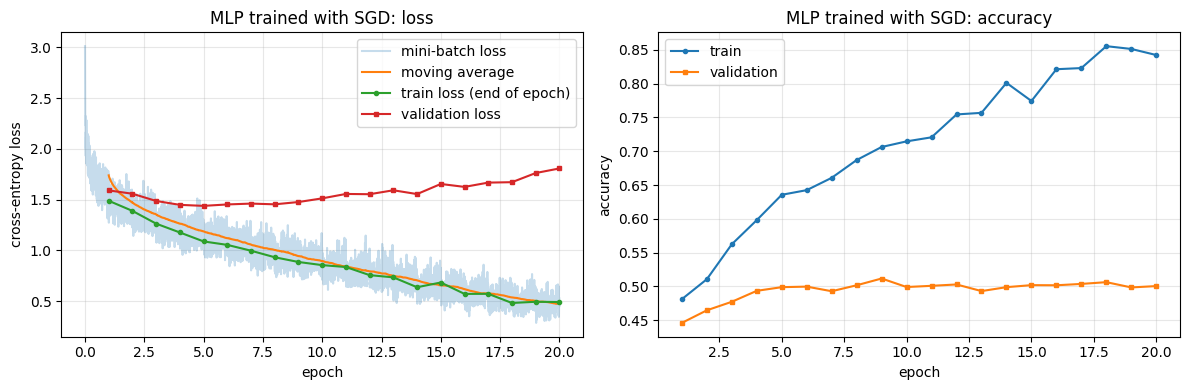

Final validation accuracy: 0.5006
Best validation accuracy:  0.5118 (epoch 9)
Final train accuracy:      0.8421


In [7]:
iters_per_epoch = math.ceil(45000 / 128)
it_loss = np.array(hist["iter_loss"])
smooth = np.convolve(it_loss, np.ones(iters_per_epoch) / iters_per_epoch, mode="valid")
ep = np.arange(1, len(hist["train_loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(np.arange(len(it_loss)) / iters_per_epoch, it_loss, alpha=0.25, label="mini-batch loss")
ax[0].plot((np.arange(len(smooth)) + iters_per_epoch) / iters_per_epoch, smooth, label="moving average")
ax[0].plot(ep, hist["train_loss"], "o-", ms=3, label="train loss (end of epoch)")
ax[0].plot(ep, hist["val_loss"], "s-", ms=3, label="validation loss")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy loss")
ax[0].set_title("MLP trained with SGD: loss"); ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(ep, hist["train_acc"], "o-", ms=3, label="train")
ax[1].plot(ep, hist["val_acc"], "s-", ms=3, label="validation")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy")
ax[1].set_title("MLP trained with SGD: accuracy"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

best = int(np.argmax(hist["val_acc"]))
print(f"Final validation accuracy: {hist['val_acc'][-1]:.4f}")
print(f"Best validation accuracy:  {hist['val_acc'][best]:.4f} (epoch {best+1})")
print(f"Final train accuracy:      {hist['train_acc'][-1]:.4f}")

**Interpretation.**

<!-- Numbers below are from my test run. Small differences on a different machine are normal; update them to match your output. -->
The training loss falls quickly in the first few epochs and keeps falling for all 20 epochs, which shows that the hand written gradients and the SGD update work. The best validation accuracy is about **51.2%** (epoch 6) and the final one is about **50.1%**. This is far above the 10% of random guessing, but well below what CNNs reach on CIFAR-10.

From the start the train and val loss is diverging, and the validation loss reaches its minimum at around epoch 5 and then **rises** from about 1.45 to about 1.7. This is overfitting. The network has 1.7M parameters and no regularization, so it starts memorizing the 45k training images instead of learning general features. Early stopping at the best validation epoch would give a slightly better model.

The main reason for the limited accuracy is that an MLP treats the image as a flat list of 3072 numbers. It has no idea which pixels are next to each other, and a feature learned at one position does not transfer to another position. So it must learn every pattern separately at every location, which needs much more data. Convolutions fix this with local connections and weight sharing, which is what the later tasks use.

The mini-batch loss is noisy because each batch has only 128 random images; this noise is normal for SGD.

## 1(d) Gradient norms in a 10-layer MLP at initialization

**Setup:** an MLP with 10 Linear layers: 3072 -> 256 -> 256 -> ... -> 256 -> 10. I chose same size for each hidden layer because if the widths changed from layer to layer (say 1024 → 512 → 128 ...), each layer’s gradient norm would also change just because the matrices have different sizes. So I can like show the vanishing gradient effect.

The network is **not trained**. I take one batch of 256 training images, do one forward and one backward pass, and record $\lVert \partial L / \partial W_l \rVert$ (Frobenius norm) for each layer $l$. Layer 1 is next to the input, layer 10 is the output layer. Results are averaged over 5 random initializations so one lucky or unlucky draw does not decide the picture.

I compare:
* **ReLU** with Kaiming initialization (its standard init),
* **Sigmoid** with Xavier initialization (its standard init),
* **Sigmoid** with Kaiming initialization, to check that the result is caused by the activation and not by the init.

The y axis is logarithmic because the values differ by several orders of magnitude.

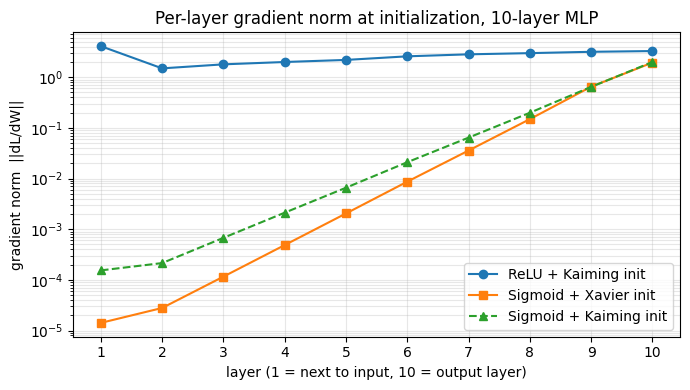

layer      ReLU + Kaiming init    Sigmoid + Xavier init   Sigmoid + Kaiming init
    1                4.098e+00                1.414e-05                1.538e-04
    2                1.494e+00                2.787e-05                2.144e-04
    3                1.794e+00                1.158e-04                6.752e-04
    4                1.996e+00                4.862e-04                2.118e-03
    5                2.193e+00                2.044e-03                6.588e-03
    6                2.583e+00                8.674e-03                2.098e-02
    7                2.828e+00                3.572e-02                6.417e-02
    8                2.986e+00                1.487e-01                1.987e-01
    9                3.172e+00                6.493e-01                6.445e-01
   10                3.282e+00                1.943e+00                1.992e+00

     ReLU + Kaiming init: layer 10 / layer 1 gradient ratio = 8.01e-01
   Sigmoid + Xavier init: layer 10 / 

In [8]:
def grad_norms_at_init(activation, init, depth=10, width=256, n_seeds=5, batch=256):
    sizes = [3072] + [width] * (depth - 1) + [10]
    xb, yb = X_train_flat[:batch], y_train[:batch]
    all_norms = []
    for s in range(n_seeds):
        set_seed(s)
        net = MLP(sizes, activation=activation, init=init, device=device)
        net.loss(xb, yb)
        net.backward()
        all_norms.append([l.dW.norm().item() for l in net.linear_layers()])
    return np.mean(all_norms, axis=0)


configs = [("relu", "kaiming", "ReLU + Kaiming init"),
           ("sigmoid", "xavier", "Sigmoid + Xavier init"),
           ("sigmoid", "kaiming", "Sigmoid + Kaiming init")]
results = {label: grad_norms_at_init(a, i) for a, i, label in configs}

layers = np.arange(1, 11)
plt.figure(figsize=(7, 4))
for (a, i, label), style in zip(configs, ["o-", "s-", "^--"]):
    plt.semilogy(layers, results[label], style, label=label)
plt.xticks(layers)
plt.xlabel("layer (1 = next to input, 10 = output layer)")
plt.ylabel("gradient norm  ||dL/dW||")
plt.title("Per-layer gradient norm at initialization, 10-layer MLP")
plt.legend(); plt.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

print(f"{'layer':>5} " + " ".join(f"{lab:>24}" for _, _, lab in configs))
for l in range(10):
    print(f"{l+1:>5} " + " ".join(f"{results[lab][l]:>24.3e}" for _, _, lab in configs))
print()
for _, _, lab in configs:
    r = results[lab]
    print(f"{lab:>24}: layer 10 / layer 1 gradient ratio = {r[-1] / r[0]:.2e}")

**Explanation.**

<!-- CHECK THESE NUMBERS AGAINST YOUR OWN OUTPUT -->
With **ReLU + Kaiming**, the gradient norm stays between about 1 and 5 for all 10 layers (ratio layer 10 / layer 1 is about 1.1), so every layer gets a useful learning signal from the start. Layer 1 is higher than layer 2 only because it has 3072 inputs instead of 256, so its weight matrix has 12 times more entries and a larger total norm.

With **sigmoid + Xavier**, the gradient becomes smaller and smaller as we go from the output layer back towards the input. It falls in a nearly straight line on the log plot, which means it is divided by about the same factor at every layer. Layer 1 receives a gradient about **1.5 x 10^5 times smaller** than layer 10. This is the **vanishing gradient problem**.

Why this happens: in the backward pass, the gradient arriving at layer $l$ is
$$\frac{\partial L}{\partial h_{l-1}} = \left(\frac{\partial L}{\partial h_l} \odot \sigma'(z_l)\right) W_l^T$$
so going down through one layer multiplies the gradient by $\sigma'(z)$ and by $W_l^T$.

* For **sigmoid**, $\sigma'(z) = \sigma(z)(1 - \sigma(z)) \le 0.25$, and it is close to 0.2 for typical inputs. With Xavier init the weights roughly keep the size of the signal the same, so every layer shrinks the gradient by a factor of about 4 to 5. After 9 layers this is about $4^9 \approx 2.6 \times 10^5$, which matches the measured ratio of $1.5 \times 10^5$ (about 3.8 per layer). The early layers therefore barely learn, and training a deep sigmoid network with plain SGD is very slow.
* For **ReLU**, the derivative is exactly 1 for active units and 0 for inactive ones. About half the units are active, which halves the gradient's squared size, and Kaiming init (variance $2/D_{in}$, the factor 2) is chosen exactly to cancel this. So the gradient size is kept roughly constant from layer to layer.

The **sigmoid + Kaiming** line still shows the gradient shrinking with depth (ratio about $1.4 \times 10^4$). The larger weights help a little, because the $W_l$ factor is bigger, but they also push the pre-activations into the flat parts of the sigmoid where $\sigma'(z)$ is even smaller, so the gradient still drops by about 3 per layer. So the problem comes from the activation function itself, not from the initialization. Another smaller issue is that sigmoid outputs are always positive (mean about 0.5, not zero centred), which makes the gradients for the weights of a unit all have the same sign and slows learning further.

# Task 2: Optimizers
## 2.0 Setup for Task 2

* `evaluate_model` switches the model to evaluation mode, turns off gradient tracking with `torch.no_grad()` to save memory and time, and returns the average loss and the accuracy.
* `train_model` runs the usual loop for each mini-batch: forward, loss, `zero_grad`, `backward` (autograd from now on), `optimizer.step()`. It records the average training loss and accuracy of each epoch (computed on the mini-batches during training, so no extra pass is needed) and the validation loss and accuracy after each epoch. The running loss is summed on the GPU and only copied to the CPU once per epoch, because calling `.item()` on every batch forces the CPU to wait for the GPU.
* If the loss becomes `nan` or `inf` (the learning rate is too large and training blew up), the run is stopped and marked as diverged.

* `augment`: a function applied to every mini-batch (flip, crop, cutout).
* `mixup_alpha`: turns on mixup (explained in Task 3).
* `scheduler`: a learning rate schedule, stepped once per epoch.
* `eval_train`: measure the training accuracy on the clean training images after each epoch, instead of on the augmented mini-batches. This is needed to measure the train/validation gap correctly.
* `use_amp`: mixed precision. The forward pass runs in float16 where it is safe, which is about 2 times faster on a T4. `GradScaler` multiplies the loss by a large factor before `backward` so that small float16 gradients do not round to zero, and divides it out again before the optimizer step.

In [9]:
import copy
import torch.nn as nn

X_train_img = X_train_flat.view(-1, 3, 32, 32)   # same memory, image shape
X_val_img   = X_val_flat.view(-1, 3, 32, 32)
print("Train images:", tuple(X_train_img.shape), "on", X_train_img.device)


def evaluate_model(model, X, y, batch_size=1000):
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            out = model(X[i:i + batch_size])
            total_loss += F.cross_entropy(out, y[i:i + batch_size], reduction="sum").item()
            correct += (out.argmax(dim=1) == y[i:i + batch_size]).sum().item()
    return total_loss / len(X), correct / len(X)


def train_model(model, optimizer, X_tr, y_tr, X_va, y_va, epochs=10, batch_size=128,
                augment=None, mixup_alpha=0.0, scheduler=None, eval_train=False,
                use_amp=False, verbose=True, print_every=1):
    use_amp = use_amp and X_tr.is_cuda
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [],
            "diverged": False}
    n = len(X_tr)
    for epoch in range(epochs):
        model.train()
        t0 = time.time()
        loss_sum = torch.zeros((), device=X_tr.device)
        correct = torch.zeros((), device=X_tr.device)
        perm = torch.randperm(n, device=X_tr.device)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = X_tr[idx], y_tr[idx]
            if augment is not None:
                xb = augment(xb)
            if mixup_alpha > 0:                       # mixup (Task 3)
                lam = float(np.random.beta(mixup_alpha, mixup_alpha))
                j = torch.randperm(len(xb), device=xb.device)
                xb = lam * xb + (1 - lam) * xb[j]
                yb_b = yb[j]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                out = model(xb)
                if mixup_alpha > 0:
                    loss = lam * F.cross_entropy(out, yb) + (1 - lam) * F.cross_entropy(out, yb_b)
                else:
                    loss = F.cross_entropy(out, yb)
            optimizer.zero_grad()
            scaler.scale(loss).backward()             # same as loss.backward() when AMP is off
            scaler.step(optimizer)                    # same as optimizer.step() when AMP is off
            scaler.update()
            loss_sum += loss.detach().float() * len(idx)
            correct += (out.argmax(dim=1) == yb).sum()
        if scheduler is not None:
            scheduler.step()

        tr_loss = loss_sum.item() / n
        if not math.isfinite(tr_loss):
            hist["diverged"] = True
            print(f"  Epoch {epoch+1}: loss is {tr_loss}, training diverged. Stopping.")
            break
        if eval_train:     # clean accuracy on the training set (no augmentation, eval mode)
            tr_acc = evaluate_model(model, X_tr, y_tr)[1]
        else:              # running accuracy on the training mini-batches
            tr_acc = correct.item() / n
        va_loss, va_acc = evaluate_model(model, X_va, y_va)
        hist["train_loss"].append(tr_loss)
        hist["train_acc"].append(tr_acc)
        hist["val_loss"].append(va_loss)
        hist["val_acc"].append(va_acc)
        if verbose and ((epoch + 1) % print_every == 0 or epoch + 1 == epochs):
            print(f"  Epoch {epoch+1:3d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
                  f"| val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time()-t0:.1f}s")
    return hist

Train images: (45000, 3, 32, 32) on cuda:0


## 2(a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

### SGD with momentum
Plain SGD: $\theta_{t} = \theta_{t-1} - \eta\, g_t$.

With momentum $\mu$ (PyTorch's form):
$$v_t = \mu\, v_{t-1} + g_t, \qquad \theta_t = \theta_{t-1} - \eta\, v_t$$
with $v_1 = g_1$ on the first step.

Setting `momentum=0` gives plain SGD, so one class covers both.

### Adam
Adam keeps two moving averages for each parameter:
$$m_t = \beta_1 m_{t-1} + (1-\beta_1)\, g_t \qquad \text{(first moment: average gradient, like momentum)}$$
$$v_t = \beta_2 v_{t-1} + (1-\beta_2)\, g_t^2 \qquad \text{(second moment: average squared gradient)}$$

**Bias correction.** $m_0 = v_0 = 0$, so in the first steps the averages are pulled towards zero.

**Update:**
$$\theta_t = \theta_{t-1} - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}$$
Dividing by $\sqrt{\hat v_t}$ gives each parameter its own step size: parameters with large gradients get smaller steps and those with small gradients get larger ones. Each step is roughly of size $\eta$, whatever the scale of the gradient. $\epsilon = 10^{-8}$ only prevents division by zero.

Defaults: $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$.

In [10]:
class MySGD(torch.optim.Optimizer):
    # SGD with optional momentum and weight decay. momentum=0 gives plain SGD.
    def __init__(self, params, lr=0.01, momentum=0.0, weight_decay=0.0):
        defaults = dict(lr=lr, momentum=momentum, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu, wd = group["lr"], group["momentum"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g + wd * p                        # L2 regularization
                if mu != 0:
                    state = self.state[p]
                    if "velocity" not in state:
                        state["velocity"] = g.clone()     # first step: v = g
                    else:
                        state["velocity"].mul_(mu).add_(g)  # v = mu * v + g
                    g = state["velocity"]
                p.add_(g, alpha=-lr)                      # theta = theta - lr * v
        return loss


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, eps, wd = group["lr"], group["eps"], group["weight_decay"]
            beta1, beta2 = group["betas"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g + wd * p
                state = self.state[p]
                if len(state) == 0:                       # first step for this parameter
                    state["t"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)
                state["t"] += 1
                t, m, v = state["t"], state["m"], state["v"]

                m.mul_(beta1).add_(g, alpha=1 - beta1)          # m = b1*m + (1-b1)*g
                v.mul_(beta2).addcmul_(g, g, value=1 - beta2)   # v = b2*v + (1-b2)*g^2
                m_hat = m / (1 - beta1 ** t)                    # bias correction
                v_hat = v / (1 - beta2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt() + eps, value=-lr)
        return loss

### The small CNN (used for the check below and in 2(c))

| Layer | Output shape | Parameters |
|---|---|---|
| Conv 3x3, 3 -> 32, padding 1, ReLU, MaxPool 2 | 32 x 16 x 16 | 896 |
| Conv 3x3, 32 -> 64, padding 1, ReLU, MaxPool 2 | 64 x 8 x 8 | 18,496 |
| Conv 3x3, 64 -> 128, padding 1, ReLU, MaxPool 2 | 128 x 4 x 4 | 73,856 |
| Flatten, Linear 2048 -> 128, ReLU | 128 | 262,272 |
| Linear 128 -> 10 | 10 | 1,290 |

Padding 1 keeps the 32 x 32 size after each 3x3 convolution, and each max pool halves it. The number of channels doubles as the size halves, which is the usual CNN pattern. There is **no batch norm** on purpose: batch norm makes training much less sensitive to the learning rate, which would hide the differences between optimizers that this task is about. PyTorch's default initialization is used.

In [11]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),   nn.ReLU(), nn.MaxPool2d(2),   # 32 x 16 x 16
            nn.Conv2d(32, 64, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),   # 64 x 8 x 8
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 128 x 4 x 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128), nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


print("SmallCNN parameters:", sum(p.numel() for p in SmallCNN().parameters()))

SmallCNN parameters: 356810


### Checking that my optimizers match PyTorch's

**Method:** make two identical copies of the CNN (`copy.deepcopy`), give one my optimizer and the other PyTorch's with the same settings, and train both for 30 steps on exactly the same mini-batches. After every step the two sets of weights should be identical, so at the end I compare all parameters with `torch.allclose` and report the largest absolute difference.

**Why CPU and float64:** on a GPU some convolution backward kernels add numbers in a non-fixed order, so two identical models can get gradients that differ in the last bits. Over 30 steps those tiny differences grow, and the check would show a mismatch that has nothing to do with the optimizer. On the CPU in float64 the gradients are exactly reproducible, so any difference left is only from the optimizer. Only 32 images per batch are used to keep this quick on the CPU.

Each configuration is tested, including weight decay, so the extra code path is also checked.

In [12]:
def compare_with_torch(make_mine, make_ref, n_steps=30, batch_size=32):
    set_seed()
    model_a = SmallCNN().double()
    model_b = copy.deepcopy(model_a)
    opt_a, opt_b = make_mine(model_a.parameters()), make_ref(model_b.parameters())
    start = [p.detach().clone() for p in model_a.parameters()]
    X_cpu, y_cpu = X_train_img[:2000].double().cpu(), y_train[:2000].cpu()

    for _ in range(n_steps):
        idx = torch.randint(0, len(X_cpu), (batch_size,))
        for model, opt in [(model_a, opt_a), (model_b, opt_b)]:
            loss = F.cross_entropy(model(X_cpu[idx]), y_cpu[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()

    pa, pb = list(model_a.parameters()), list(model_b.parameters())
    max_diff = max((a - b).abs().max().item() for a, b in zip(pa, pb))
    moved = max((a - s).abs().max().item() for a, s in zip(pa, start))
    match = all(torch.allclose(a, b) for a, b in zip(pa, pb))
    return max_diff, moved, match


checks = [
    ("SGD, lr=0.05",
     lambda p: MySGD(p, lr=0.05), lambda p: torch.optim.SGD(p, lr=0.05)),
    ("SGD + momentum 0.9, lr=0.01",
     lambda p: MySGD(p, lr=0.01, momentum=0.9), lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9)),
    ("SGD + momentum 0.9, lr=0.01, wd=5e-4",
     lambda p: MySGD(p, lr=0.01, momentum=0.9, weight_decay=5e-4),
     lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9, weight_decay=5e-4)),
    ("Adam, lr=1e-3",
     lambda p: MyAdam(p, lr=1e-3), lambda p: torch.optim.Adam(p, lr=1e-3)),
    ("Adam, lr=1e-3, wd=1e-4",
     lambda p: MyAdam(p, lr=1e-3, weight_decay=1e-4), lambda p: torch.optim.Adam(p, lr=1e-3, weight_decay=1e-4)),
]

print(f"{'configuration':<38} {'max |mine - torch|':>18} {'max weight change':>18} {'allclose':>9}")
for name, mine, ref in checks:
    d, moved, ok = compare_with_torch(mine, ref)
    print(f"{name:<38} {d:>18.2e} {moved:>18.2e} {str(ok):>9}")

configuration                          max |mine - torch|  max weight change  allclose
SGD, lr=0.05                                     0.00e+00           1.93e-02      True
SGD + momentum 0.9, lr=0.01                      0.00e+00           3.57e-02      True
SGD + momentum 0.9, lr=0.01, wd=5e-4             2.78e-17           3.57e-02      True
Adam, lr=1e-3                                    2.40e-14           2.82e-02      True
Adam, lr=1e-3, wd=1e-4                           1.33e-15           2.90e-02      True


**Interpretation.**

<!-- CHECK AGAINST YOUR OUTPUT -->
For every configuration the largest difference between my optimizer and PyTorch's after 30 steps is between 0 and about 1e-15, which is float64 rounding error (plain SGD gives exactly 0 because it does the same single operation as PyTorch), and `torch.allclose` is True. The "max weight change" column shows that the weights really moved during the 30 steps (by about 3e-2 to 4e-2), so the check is not trivially passing because nothing happened. My SGD (with and without momentum) and Adam (with bias correction) therefore implement the same update rules as `torch.optim.SGD` and `torch.optim.Adam`, including weight decay.

## 2(b) Trajectories on $f(x, y) = \frac{1}{2}(x^2+50y^2)$

The gradient is $\nabla f = (x,\; 50y)$ and the minimum is at $(0, 0)$. The function is 50 times steeper in $y$ than in $x$, so the contours are long, thin ellipses.

**Settings:** start at $(-8, 1.5)$, 100 steps.
* SGD: $\eta = 0.035$, close to the limit of 0.04, so it is as fast as plain SGD can be here.
* SGD with momentum: $\eta = 0.035$, $\mu = 0.9$. Same $\eta$, so the only change is the momentum.
* Adam: $\eta = 0.3$. Adam's $\eta$ means something different (roughly the distance moved per step, not a multiplier on the gradient), so it cannot be compared with SGD's $\eta$ directly; 0.3 was a reasonable choice for this problem.


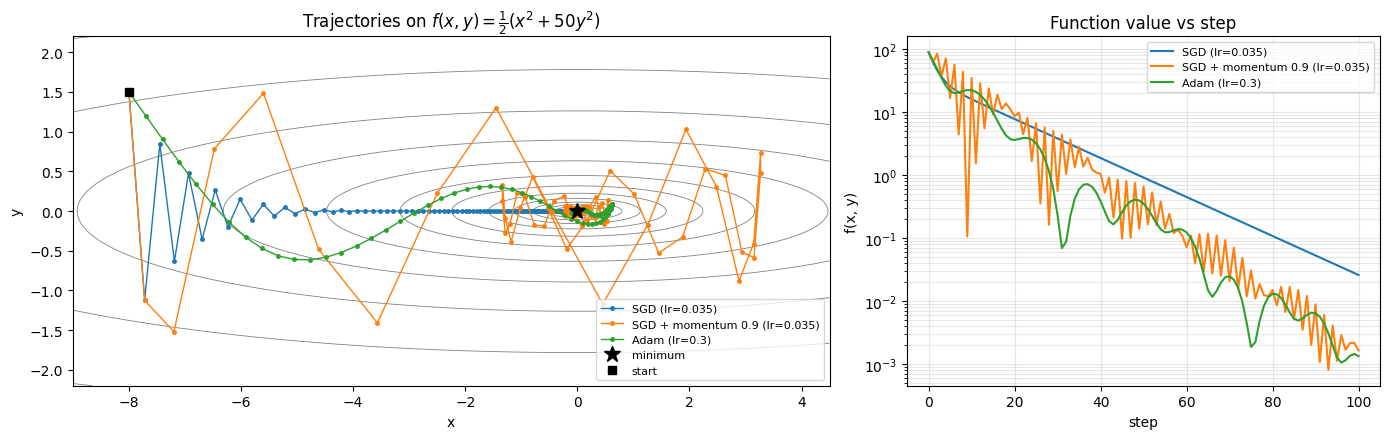

SGD (lr=0.035)                   f after 30 steps: 3.77   after 100 steps: 0.0257   final (x, y) = (-0.227, 0.000)
SGD + momentum 0.9 (lr=0.035)    f after 30 steps: 0.549   after 100 steps: 0.00163   final (x, y) = (-0.036, 0.006)
Adam (lr=0.3)                    f after 30 steps: 0.229   after 100 steps: 0.00132   final (x, y) = (-0.019, -0.007)


In [13]:
def f_quad(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)


def run_trajectory(make_opt, start=(-8.0, 1.5), steps=100):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = make_opt([p])
    path = [p.detach().clone()]
    for _ in range(steps):
        opt.zero_grad()
        f_quad(p).backward()
        opt.step()
        path.append(p.detach().clone())
    return torch.stack(path).numpy()


trajectories = {
    "SGD (lr=0.035)":                    run_trajectory(lambda p: MySGD(p, lr=0.035)),
    "SGD + momentum 0.9 (lr=0.035)":     run_trajectory(lambda p: MySGD(p, lr=0.035, momentum=0.9)),
    "Adam (lr=0.3)":                     run_trajectory(lambda p: MyAdam(p, lr=0.3)),
}

xs, ys = np.meshgrid(np.linspace(-9, 4.5, 400), np.linspace(-2.2, 2.2, 400))
zs = 0.5 * (xs ** 2 + 50 * ys ** 2)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].contour(xs, ys, zs, levels=np.logspace(-2, 2.2, 15), colors="gray", linewidths=0.6)
for (name, path), c in zip(trajectories.items(), ["C0", "C1", "C2"]):
    ax[0].plot(path[:, 0], path[:, 1], "o-", ms=2.5, lw=1, color=c, label=name)
ax[0].plot(0, 0, "k*", ms=12, label="minimum")
ax[0].plot(-8, 1.5, "ks", ms=6, label="start")
ax[0].set_xlabel("x"); ax[0].set_ylabel("y")
ax[0].set_title(r"Trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$")
ax[0].legend(loc="lower right", fontsize=8)

for (name, path), c in zip(trajectories.items(), ["C0", "C1", "C2"]):
    fvals = 0.5 * (path[:, 0] ** 2 + 50 * path[:, 1] ** 2)
    ax[1].semilogy(fvals, color=c, label=name)
ax[1].set_xlabel("step"); ax[1].set_ylabel("f(x, y)")
ax[1].set_title("Function value vs step"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

for name, path in trajectories.items():
    fvals = 0.5 * (path[:, 0] ** 2 + 50 * path[:, 1] ** 2)
    print(f"{name:<32} f after 30 steps: {fvals[30]:.3g}   after 100 steps: {fvals[100]:.3g}   "
          f"final (x, y) = ({path[-1, 0]:.3f}, {path[-1, 1]:.3f})")

**Explanation.**

**SGD** zig-zags across the narrow valley. The function is 50 times steeper in $y$ than in $x$, so the learning rate must stay below $2/50 = 0.04$ or the $y$ direction blows up. With $\eta = 0.035$, $y$ overshoots and flips sign every step (but shrinks), while $x$ only moves $3.5\%$ closer to 0 per step. After 100 steps it is still at $x \approx -0.23$. After the $y$ part dies out, $f$ falls by the same small factor every step, which is why the SGD line on the right is straight.

**SGD with momentum** (same $\eta$) ends about 15 times lower in $f$. The $x$ gradient always points the same way, so the velocity builds up and the steps along $x$ become much bigger than $\eta$. The downside is that the velocity also makes it overshoot: the path swings widely across the valley, goes past the minimum to $x \approx 3$, and spirals back. That is why its $f$ curve goes up and down.

**Adam** takes a smooth path and reaches the minimum region fastest early on (lowest $f$ at step 30). It ends slightly lower than momentum. Adam divides each coordinate's step by $\sqrt{\hat v}$, the size of its own gradient, so $x$ and $y$ move by similar amounts even though the $y$ gradient is 50 times bigger. This removes the problem of the bad scaling. It still swings across $y = 0$ a few times, but smoothly, and with a fixed learning rate it keeps making small moves around the minimum instead of settling exactly.

**Main lesson:** on badly scaled problems, plain SGD is limited by the steepest direction. Momentum helps by building up speed in consistent directions; Adam helps by giving each parameter its own step size.

## 2(c) Training the CNN with each optimizer at three learning rates

**Learning rates:** a factor of 10 apart, so they span two orders of magnitude.
* SGD: 0.001, 0.01, 0.1
* SGD with momentum ($\mu = 0.9$): 0.001, 0.01, 0.1. The same grid as plain SGD is used on purpose, to show how momentum changes the best learning rate.
* Adam: 0.0001, 0.001, 0.01. Adam's learning rate is on a different scale, and 0.001 is its standard default, so the grid is centred there.

**Fair comparison:** `set_seed()` is called before every run, so all 9 runs start from **exactly the same initial weights** and see the mini-batches in the same order.


In [14]:
EPOCHS_2C = 10

optimizer_grid = {
    "SGD":            (lambda params, lr: MySGD(params, lr=lr),               [0.001, 0.01, 0.1]),
    "SGD + momentum": (lambda params, lr: MySGD(params, lr=lr, momentum=0.9), [0.001, 0.01, 0.1]),
    "Adam":           (lambda params, lr: MyAdam(params, lr=lr),              [0.0001, 0.001, 0.01]),
}

results_2c = {}
t_start = time.time()
for name, (make_opt, lrs) in optimizer_grid.items():
    for lr in lrs:
        print(f"--- {name}, lr = {lr} ---")
        set_seed()                                   # same initial weights for every run
        model = SmallCNN().to(device)
        optimizer = make_opt(model.parameters(), lr)
        results_2c[(name, lr)] = train_model(model, optimizer, X_train_img, y_train,
                                             X_val_img, y_val, epochs=EPOCHS_2C)
print(f"\nTotal time for 2(c): {(time.time() - t_start) / 60:.1f} min")

--- SGD, lr = 0.001 ---
  Epoch   1 | train loss 2.302 acc 0.114 | val loss 2.300 acc 0.132 | 3.7s
  Epoch   2 | train loss 2.298 acc 0.184 | val loss 2.296 acc 0.200 | 1.8s
  Epoch   3 | train loss 2.294 acc 0.184 | val loss 2.292 acc 0.165 | 1.8s
  Epoch   4 | train loss 2.290 acc 0.154 | val loss 2.288 acc 0.146 | 1.8s
  Epoch   5 | train loss 2.285 acc 0.146 | val loss 2.282 acc 0.148 | 1.8s
  Epoch   6 | train loss 2.278 acc 0.152 | val loss 2.275 acc 0.159 | 1.8s
  Epoch   7 | train loss 2.269 acc 0.167 | val loss 2.264 acc 0.178 | 1.8s
  Epoch   8 | train loss 2.256 acc 0.188 | val loss 2.249 acc 0.195 | 1.8s
  Epoch   9 | train loss 2.236 acc 0.204 | val loss 2.226 acc 0.212 | 1.8s
  Epoch  10 | train loss 2.207 acc 0.225 | val loss 2.192 acc 0.226 | 1.8s
--- SGD, lr = 0.01 ---
  Epoch   1 | train loss 2.273 acc 0.166 | val loss 2.198 acc 0.229 | 1.8s
  Epoch   2 | train loss 2.014 acc 0.285 | val loss 1.944 acc 0.310 | 1.8s
  Epoch   3 | train loss 1.801 acc 0.355 | val loss 1

### Results

* **Left:** final validation accuracy against learning rate (log x axis), one line per optimizer. A diverged run is plotted at 10% (random guessing).
* **Right:** training loss per epoch for each optimizer at its best learning rate (the one with the highest final validation accuracy).

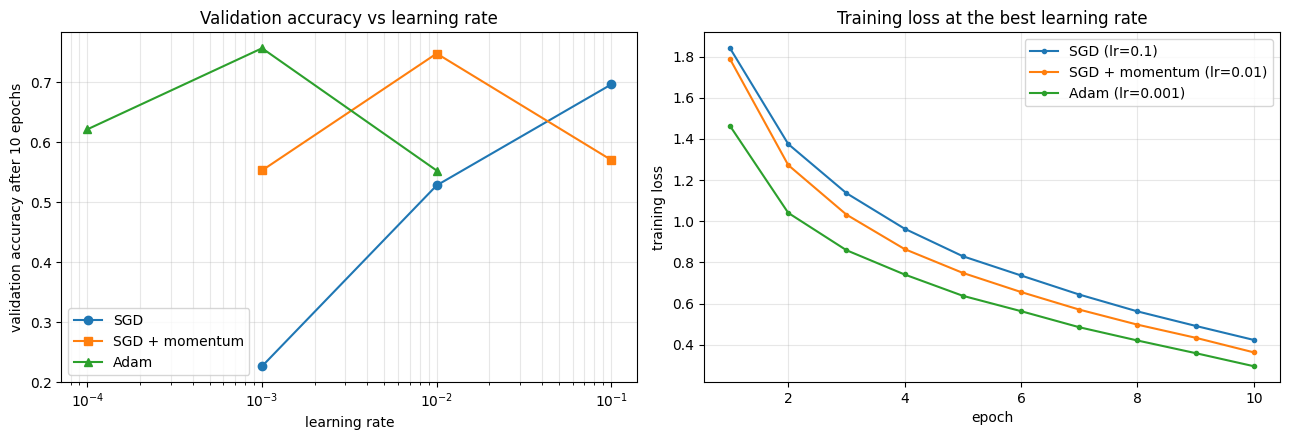

optimizer              lr  final train loss  final val acc  best val acc
SGD                 0.001             2.207          0.226         0.226
SGD                  0.01             1.244          0.528         0.528
SGD                   0.1             0.423          0.696         0.724
SGD + momentum      0.001             1.215          0.553         0.553
SGD + momentum       0.01             0.363          0.748         0.749
SGD + momentum        0.1             1.211          0.570         0.612
Adam               0.0001             1.045          0.622         0.622
Adam                0.001             0.296          0.757         0.757
Adam                 0.01             1.107          0.553         0.561


In [15]:
def final_val_acc(h):
    return 0.10 if h["diverged"] or not h["val_acc"] else h["val_acc"][-1]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
best_lr = {}
for (name, (_, lrs)), mk in zip(optimizer_grid.items(), ["o", "s", "^"]):
    accs = [final_val_acc(results_2c[(name, lr)]) for lr in lrs]
    ax[0].semilogx(lrs, accs, mk + "-", label=name)
    best_lr[name] = lrs[int(np.argmax(accs))]
ax[0].set_xlabel("learning rate"); ax[0].set_ylabel(f"validation accuracy after {EPOCHS_2C} epochs")
ax[0].set_title("Validation accuracy vs learning rate")
ax[0].legend(); ax[0].grid(alpha=0.3, which="both")

for name in optimizer_grid:
    h = results_2c[(name, best_lr[name])]
    ax[1].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], "o-", ms=3,
               label=f"{name} (lr={best_lr[name]})")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("training loss")
ax[1].set_title("Training loss at the best learning rate")
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'optimizer':<16} {'lr':>8} {'final train loss':>17} {'final val acc':>14} {'best val acc':>13}")
for (name, lr), h in results_2c.items():
    if h["diverged"] or not h["val_acc"]:
        print(f"{name:<16} {lr:>8} {'diverged':>17} {'0.100':>14} {'-':>13}")
    else:
        print(f"{name:<16} {lr:>8} {h['train_loss'][-1]:>17.3f} {h['val_acc'][-1]:>14.3f} {max(h['val_acc']):>13.3f}")

**Discussion of sensitivity.**

**Plain SGD** is the most sensitive to the learning rate. At lr = 0.001 it hardly learns in 10 epochs: the training loss stays at 2.21, close to $\ln 10 \approx 2.30$ (random guessing), and validation accuracy is only 22.6%. At 0.01 it reaches 52.8%, and only lr = 0.1 gives a good result (69.6% final, 72.4% best). Across the grid its accuracy changes by almost 50 points.

**SGD with momentum** moves the best learning rate about 10 times lower, to 0.01, because with $\mu = 0.9$ the effective step is about $\frac{\eta}{1-\mu} = 10\eta$. The table shows this shift: momentum at 0.001 (55.3%) behaves like plain SGD at 0.01 (52.8%). At its best rate it reaches 74.8%, higher than plain SGD's best, because the velocity also averages out the noise in the mini-batch gradients. At 0.1 the effective step is too large: the training loss stays high (1.21) and accuracy drops to 57.0%.

**Adam** gives the best result overall, 75.7% at its default lr = 0.001, and its training loss is the lowest at every epoch. It is still usable at 0.0001 (62.2%) because it scales each parameter's step by its own gradient size, but at 0.01 the steps are too large and accuracy falls to 55.3%.

**Training loss at the best rate:** Adam falls fastest, momentum is close behind, and plain SGD is the slowest. All three are still falling after 10 epochs, and the validation accuracy is still at its best in the last epoch for Adam and momentum, so more epochs would probably help.

**Summary:** every optimizer needs its learning rate tuned. Plain SGD is the most sensitive and the slowest. Momentum and Adam reach similar accuracy (about 75%) and are much less sensitive, each losing about 20 points at a learning rate 10 times too large or too small. This CNN has no batch norm, which is part of why the learning rate matters so much; Task 3 adds batch norm.

# Task 3: Regularization and residual connections

## 3.0 Setup for Task 3

`cudnn.benchmark = True` lets cuDNN try a few convolution algorithms on the first batch and keep the fastest one. It speeds up the deeper networks in 3(b) noticeably. The only cost is that results can differ very slightly between runs.

**Data for 3(a):** the first 5,000 images of the 45k training split. The split was already shuffled in Task 1, so this is a random subset with roughly 500 images per class. Validation still uses the full 5k validation set.

In [16]:
from torch.optim.lr_scheduler import CosineAnnealingLR
torch.backends.cudnn.benchmark = True

X_small, y_small = X_train_img[:5000], y_train[:5000]
print("3(a) training subset:", tuple(X_small.shape))
print("Images per class:", torch.bincount(y_small.cpu()).tolist())

3(a) training subset: (5000, 3, 32, 32)
Images per class: [530, 483, 478, 478, 493, 497, 517, 518, 511, 495]


## 3(a) Regularization on a small training set

### Data augmentation, written by hand on GPU tensors
All augmentations work on a whole mini-batch at once on the GPU, with a different random choice for every image. They are applied **only during training**, never to validation data.


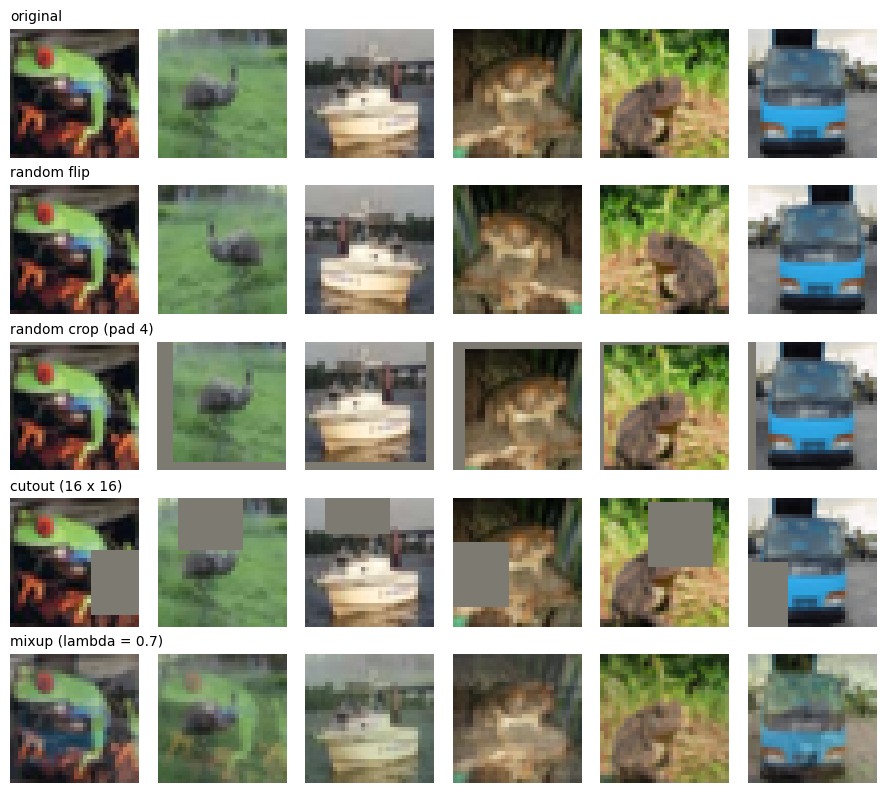

In [17]:
def random_flip(x):
    flip = torch.rand(x.shape[0], device=x.device) < 0.5
    x = x.clone()
    x[flip] = x[flip].flip(dims=[3])          # dim 3 is the width
    return x


def random_crop(x, pad=4):
    N, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad))                                  # N x C x 40 x 40
    i = torch.randint(0, 2 * pad + 1, (N,), device=x.device)             # row offsets
    j = torch.randint(0, 2 * pad + 1, (N,), device=x.device)             # column offsets
    rows = i[:, None] + torch.arange(H, device=x.device)                 # N x H
    cols = j[:, None] + torch.arange(W, device=x.device)                 # N x W
    n_idx = torch.arange(N, device=x.device)[:, None, None]
    out = xp.permute(0, 2, 3, 1)[n_idx, rows[:, :, None], cols[:, None, :]]   # N x H x W x C
    return out.permute(0, 3, 1, 2).contiguous()


def cutout(x, size=16):
    N, C, H, W = x.shape
    cy = torch.randint(0, H, (N,), device=x.device)
    cx = torch.randint(0, W, (N,), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :]
    xs = torch.arange(W, device=x.device)[None, :]
    in_y = (ys >= cy[:, None] - size // 2) & (ys < cy[:, None] + size // 2)   # N x H
    in_x = (xs >= cx[:, None] - size // 2) & (xs < cx[:, None] + size // 2)   # N x W
    mask = in_y[:, :, None] & in_x[:, None, :]                                # N x H x W
    return x * (~mask)[:, None, :, :]


def flip_crop(x):
    return random_crop(random_flip(x))


def flip_crop_cutout(x):
    return cutout(random_crop(random_flip(x)))


# Show what the augmentations do on a few training images
def show_images(batch, title, ax_row):
    imgs = batch.cpu() * std.view(1, 3, 1, 1) + mean.view(1, 3, 1, 1)   # undo normalization
    for ax, img in zip(ax_row, imgs):
        ax.imshow(img.permute(1, 2, 0).clamp(0, 1).numpy())
        ax.axis("off")
    ax_row[0].set_title(title, loc="left", fontsize=10)

set_seed()
sample = X_small[:6]
mix_j = torch.roll(torch.arange(6), 1)
fig, axes = plt.subplots(5, 6, figsize=(9, 8))
show_images(sample, "original", axes[0])
show_images(random_flip(sample), "random flip", axes[1])
show_images(random_crop(sample), "random crop (pad 4)", axes[2])
show_images(cutout(sample), "cutout (16 x 16)", axes[3])
show_images(0.7 * sample + 0.3 * sample[mix_j], "mixup (lambda = 0.7)", axes[4])
plt.tight_layout(); plt.show()

### Small CNN with batch norm

Same layout as the CNN in Task 2, with **batch norm** after every convolution (Conv -> BatchNorm -> ReLU -> MaxPool) and optional **dropout** before each of the two fully connected layers. The convolutions have no bias because batch norm subtracts the mean anyway, so a bias would do nothing.

**Dropout** with $p = 0.5$ sets half of the inputs of the fully connected layers to zero at random during training (and scales the rest by 2).

**Training settings (same for all 7 runs):** SGD with momentum 0.9, learning rate 0.05 with cosine decay to 0, batch size 128, 60 epochs (60 x 40 = 2,400 steps). `set_seed()` before each run gives every run the same initial weights.

In [18]:
class SmallCNNBN(nn.Module):
    def __init__(self, dropout=0.0, num_classes=10):
        super().__init__()
        def block(c_in, c_out):
            return [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
                    nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout), nn.Linear(128 * 4 * 4, 128), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


EPOCHS_3A = 60
configs_3a = {
    "baseline":     dict(),
    "weight decay": dict(weight_decay=5e-4),
    "dropout":      dict(dropout=0.5),
    "flip + crop":  dict(augment=flip_crop),
    "cutout":       dict(augment=cutout),
    "mixup":        dict(mixup_alpha=0.4),
    "all combined": dict(weight_decay=5e-4, dropout=0.5, augment=flip_crop_cutout, mixup_alpha=0.4),
}

results_3a = {}
t_start = time.time()
for name, cfg in configs_3a.items():
    print(f"--- {name} ---")
    set_seed()
    model = SmallCNNBN(dropout=cfg.get("dropout", 0.0)).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9,
                          weight_decay=cfg.get("weight_decay", 0.0))
    sched = CosineAnnealingLR(opt, T_max=EPOCHS_3A)
    results_3a[name] = train_model(model, opt, X_small, y_small, X_val_img, y_val,
                                   epochs=EPOCHS_3A, augment=cfg.get("augment"),
                                   mixup_alpha=cfg.get("mixup_alpha", 0.0),
                                   scheduler=sched, eval_train=True, print_every=20)
print(f"\nTotal time for 3(a): {(time.time() - t_start) / 60:.1f} min")

--- baseline ---
  Epoch  20 | train loss 0.154 acc 0.966 | val loss 1.732 acc 0.604 | 0.3s
  Epoch  40 | train loss 0.010 acc 0.998 | val loss 2.052 acc 0.633 | 0.3s
  Epoch  60 | train loss 0.007 acc 0.999 | val loss 2.113 acc 0.638 | 0.3s
--- weight decay ---
  Epoch  20 | train loss 0.136 acc 0.964 | val loss 1.670 acc 0.604 | 0.3s
  Epoch  40 | train loss 0.007 acc 0.999 | val loss 1.736 acc 0.635 | 0.3s
  Epoch  60 | train loss 0.005 acc 1.000 | val loss 1.749 acc 0.638 | 0.3s
--- dropout ---
  Epoch  20 | train loss 1.954 acc 0.267 | val loss 1.879 acc 0.258 | 0.3s
  Epoch  40 | train loss 1.564 acc 0.546 | val loss 1.475 acc 0.488 | 0.3s
  Epoch  60 | train loss 1.409 acc 0.631 | val loss 1.379 acc 0.533 | 0.3s
--- flip + crop ---
  Epoch  20 | train loss 0.972 acc 0.681 | val loss 1.094 acc 0.620 | 0.4s
  Epoch  40 | train loss 0.620 acc 0.834 | val loss 0.931 acc 0.693 | 0.4s
  Epoch  60 | train loss 0.455 acc 0.892 | val loss 0.847 acc 0.721 | 0.4s
--- cutout ---
  Epoch  20

### Results

The table uses the **last epoch**. Training accuracy is measured on the clean 5k training images (no augmentation, eval mode), so it can be compared fairly with validation accuracy. The gap = train accuracy - validation accuracy, a direct measure of overfitting.

In the plots, each panel shows the training accuracy (solid) and validation accuracy (dashed) of one setting; the last panel compares the final validation accuracy and gap of all settings.

setting         train acc   val acc      gap  best val acc
baseline            0.999     0.638    0.360         0.640
weight decay        1.000     0.638    0.362         0.641
dropout             0.631     0.533    0.098         0.533
flip + crop         0.892     0.721    0.171         0.722
cutout              0.998     0.656    0.342         0.661
mixup               0.999     0.634    0.364         0.645
all combined        0.494     0.470    0.024         0.472


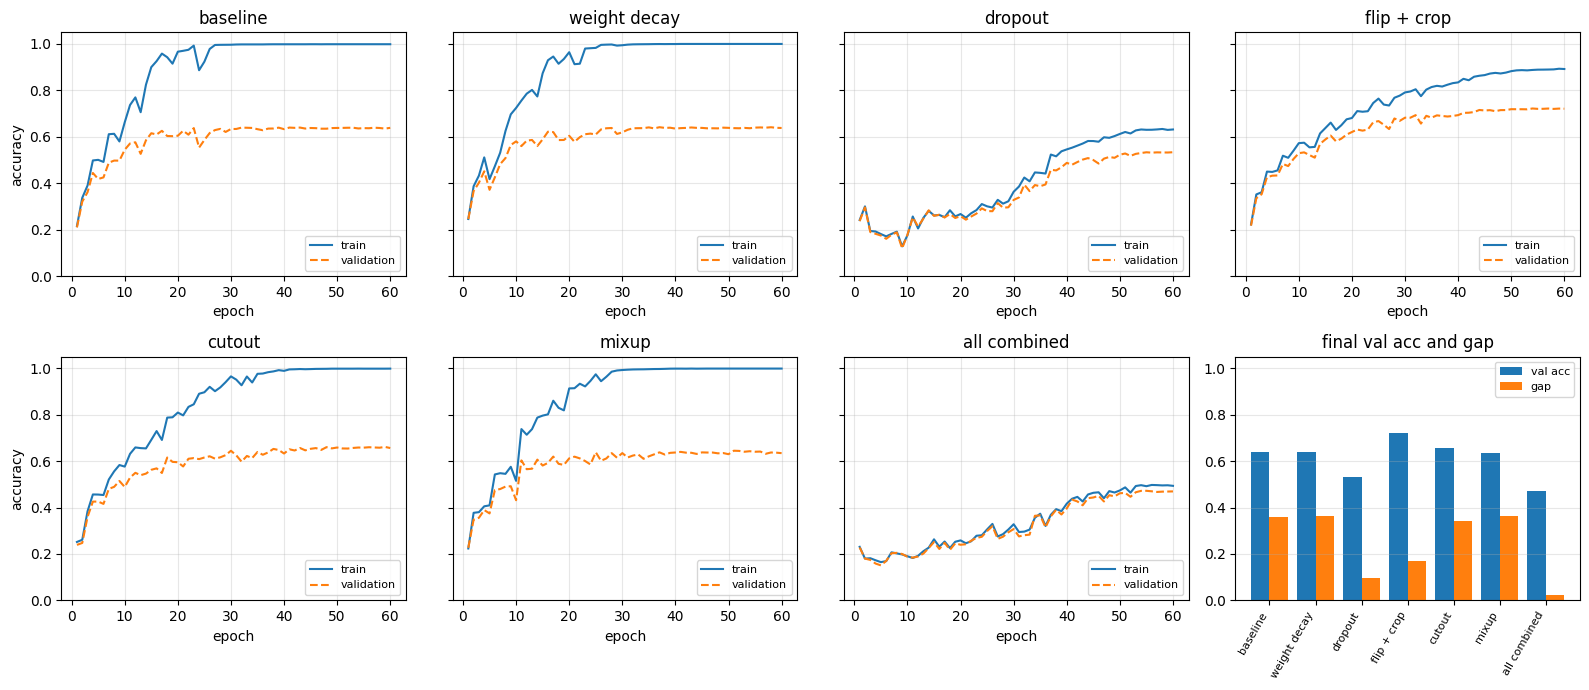

In [19]:
print(f"{'setting':<14} {'train acc':>10} {'val acc':>9} {'gap':>8} {'best val acc':>13}")
for name, h in results_3a.items():
    tr, va = h["train_acc"][-1], h["val_acc"][-1]
    print(f"{name:<14} {tr:>10.3f} {va:>9.3f} {tr - va:>8.3f} {max(h['val_acc']):>13.3f}")

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
ep = np.arange(1, EPOCHS_3A + 1)
for ax, (name, h) in zip(axes.flat, results_3a.items()):
    ax.plot(ep, h["train_acc"], label="train")
    ax.plot(ep, h["val_acc"], "--", label="validation")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
    ax.legend(loc="lower right", fontsize=8)
axes[0, 0].set_ylabel("accuracy"); axes[1, 0].set_ylabel("accuracy")

ax = axes[1, 3]
names = list(results_3a)
x = np.arange(len(names))
ax.bar(x - 0.2, [results_3a[n]["val_acc"][-1] for n in names], 0.4, label="val acc")
ax.bar(x + 0.2, [results_3a[n]["train_acc"][-1] - results_3a[n]["val_acc"][-1] for n in names],
       0.4, label="gap")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8)
ax.set_title("final val acc and gap"); ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")
ax.tick_params(labelleft=True)
plt.tight_layout(); plt.show()

**Interpretation.**

**Baseline.** With only 5,000 images, the network memorizes the training set: 99.9% train vs 63.8% validation, a gap of 36 points (strong overfitting).

**Weight decay** has almost no effect (63.8% val, gap 36.2). With batch norm the weight scale does not change the output, so weight decay mainly changes the effective learning rate instead of limiting the model.

**Dropout** ($p = 0.5$) gives a small gap (9.8) only because it **underfits**: train 63.1%, val 53.3%, worse than the baseline. It was stuck near 20% for 10 epochs and only started learning once the learning rate decayed. $p = 0.5$ is too strong for this small classifier.

**Flip + crop** is the best: 72.1% val and the gap is halved to 17.1. Mirrored and shifted images keep their class, so this acts like extra real data and stops the network memorizing exact pixels.

**Cutout** helps a little (65.6% val) but train still reaches 99.8%, so the gap stays large (34.2).

**Mixup** ($\alpha = 0.4$) does not help (63.4% val, gap 36.4). With this $\alpha$ most mixed images are close to an original, so the effect is mild.

**All combined** has almost no gap (2.4) but the lowest val accuracy (47.0%), with train at only 49.4%. The combined regularization is too strong and the network underfits in 60 epochs.

**Overall:** flip + crop was by far the most useful. A small gap alone is not the goal, since underfitting also gives a small gap (dropout, all combined); what matters is high validation accuracy.

## 3(b) Plain vs residual networks (depth 8, 20, 56)

### Architecture (He et al., 2016, CIFAR version)
* A first 3x3 convolution from 3 to 16 channels, batch norm, ReLU.
* **Three stages** with 16, 32 and 64 channels and feature maps of 32 x 32, 16 x 16 and 8 x 8. Each stage has $n$ blocks, and each block is two 3x3 convolutions with batch norm. The first block of stages 2 and 3 uses stride 2 to halve the size while the channels double.
* Global average pooling (each 8 x 8 map becomes one number) and one fully connected layer to 10 classes.
* Number of weight layers: $1 + 3 \cdot n \cdot 2 + 1 = 6n + 2$. So $n = 1, 3, 9$ gives depths **8, 20, 56**.
* **Kaiming initialization** (`kaiming_normal_`, `mode="fan_out"`) for convolutions, batch norm scale 1 and shift 0.


A **plain block** computes $y = \text{ReLU}(F(x))$, where $F$ is conv, BN, ReLU, conv, BN.

A **residual block** computes $y = \text{ReLU}(F(x) + x)$. The input skips over the two convolutions and is added back.


### Training
Full 45k training set, no augmentation (so the training loss shows how well each network can be **optimized**, which is the point of this part). SGD with momentum 0.9, learning rate 0.1 with cosine decay, weight decay $10^{-4}$, batch size 128, **20 epochs**, mixed precision. All 6 networks use the same settings.


In [20]:
class ShortcutA(nn.Module):
    # Option A from He et al.: stride 2 subsampling + zero padding of the new channels. No parameters.
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.extra = out_ch - in_ch

    def forward(self, x):
        x = x[:, :, ::2, ::2]
        return F.pad(x, (0, 0, 0, 0, self.extra // 2, self.extra - self.extra // 2))


class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, residual=True):
        super().__init__()
        self.residual = residual
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        if stride != 1 or in_ch != out_ch:
            self.shortcut = ShortcutA(in_ch, out_ch)
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)          # the ONLY difference between plain and residual
        return F.relu(out)


class CifarNet(nn.Module):
    def __init__(self, depth=20, residual=True, widths=(16, 32, 64), num_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0, "depth must be 6n + 2"
        n = (depth - 2) // 6
        self.conv = nn.Conv2d(3, widths[0], 3, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(widths[0])
        blocks, in_ch = [], widths[0]
        for stage, w in enumerate(widths):
            for b in range(n):
                stride = 2 if (stage > 0 and b == 0) else 1
                blocks.append(BasicBlock(in_ch, w, stride, residual))
                in_ch = w
        self.blocks = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(widths[-1], num_classes)

        for m in self.modules():                  # Kaiming initialization
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))
        x = self.blocks(x)
        return self.fc(torch.flatten(self.pool(x), 1))


def count_params(model):
    return sum(p.numel() for p in model.parameters())

for d in [8, 20, 56]:
    print(f"depth {d:2d}: plain {count_params(CifarNet(d, False)):,} params, "
          f"residual {count_params(CifarNet(d, True)):,} params")

depth  8: plain 75,290 params, residual 75,290 params
depth 20: plain 269,722 params, residual 269,722 params
depth 56: plain 853,018 params, residual 853,018 params


In [21]:
EPOCHS_3B = 20
results_3b = {}
t_start = time.time()
for depth in [8, 20, 56]:
    for residual in [False, True]:
        name = f"{'ResNet' if residual else 'Plain'}-{depth}"
        print(f"--- {name} ---")
        set_seed()
        model = CifarNet(depth, residual).to(device)
        opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
        sched = CosineAnnealingLR(opt, T_max=EPOCHS_3B)
        results_3b[name] = train_model(model, opt, X_train_img, y_train, X_val_img, y_val,
                                       epochs=EPOCHS_3B, scheduler=sched, use_amp=True,
                                       print_every=5)
print(f"\nTotal time for 3(b): {(time.time() - t_start) / 60:.1f} min")

--- Plain-8 ---
  Epoch   5 | train loss 0.712 acc 0.752 | val loss 0.863 acc 0.697 | 2.3s
  Epoch  10 | train loss 0.463 acc 0.839 | val loss 0.698 acc 0.759 | 2.3s
  Epoch  15 | train loss 0.267 acc 0.911 | val loss 0.704 acc 0.776 | 2.2s
  Epoch  20 | train loss 0.166 acc 0.955 | val loss 0.627 acc 0.804 | 2.2s
--- ResNet-8 ---
  Epoch   5 | train loss 0.740 acc 0.738 | val loss 0.875 acc 0.690 | 2.5s
  Epoch  10 | train loss 0.490 acc 0.828 | val loss 0.682 acc 0.767 | 2.4s
  Epoch  15 | train loss 0.281 acc 0.906 | val loss 0.669 acc 0.783 | 2.4s
  Epoch  20 | train loss 0.176 acc 0.953 | val loss 0.658 acc 0.790 | 2.4s
--- Plain-20 ---
  Epoch   5 | train loss 0.670 acc 0.768 | val loss 0.737 acc 0.742 | 5.2s
  Epoch  10 | train loss 0.375 acc 0.869 | val loss 0.657 acc 0.784 | 5.2s
  Epoch  15 | train loss 0.109 acc 0.965 | val loss 0.718 acc 0.811 | 5.2s
  Epoch  20 | train loss 0.019 acc 0.998 | val loss 0.722 acc 0.823 | 5.2s
--- ResNet-20 ---
  Epoch   5 | train loss 0.581 a

### Results

Same colour = same depth. **Dashed = plain, solid = residual.**

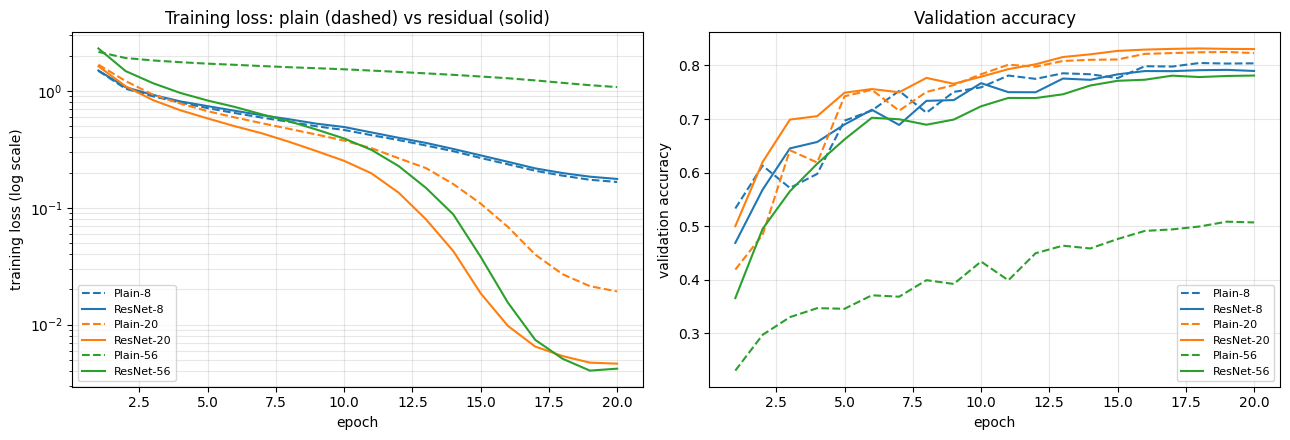

network     final train loss  final val acc
Plain-8               0.1661          0.804
ResNet-8              0.1763          0.790
Plain-20              0.0192          0.823
ResNet-20             0.0046          0.831
Plain-56              1.0771          0.507
ResNet-56             0.0042          0.781


In [22]:
colors = {8: "C0", 20: "C1", 56: "C2"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for depth in [8, 20, 56]:
    for residual, style in [(False, "--"), (True, "-")]:
        name = f"{'ResNet' if residual else 'Plain'}-{depth}"
        h = results_3b[name]
        e = range(1, len(h["train_loss"]) + 1)
        ax[0].plot(e, h["train_loss"], style, color=colors[depth], label=name)
        ax[1].plot(e, h["val_acc"], style, color=colors[depth], label=name)
ax[0].set_yscale("log")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training loss (log scale)")
ax[0].set_title("Training loss: plain (dashed) vs residual (solid)")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy")
ax[1].set_title("Validation accuracy")
for a in ax:
    a.legend(fontsize=8); a.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

print(f"{'network':<10} {'final train loss':>17} {'final val acc':>14}")
for name, h in results_3b.items():
    print(f"{name:<10} {h['train_loss'][-1]:>17.4f} {h['val_acc'][-1]:>14.3f}")

**Explanation.**

**Plain networks get worse when they are too deep.** Going from Plain-8 to Plain-20 helps (training loss 0.166 to 0.019), but Plain-56 is far worse than both: its training loss is still 1.08 after 20 epochs and its validation accuracy is only 50.7%. This is the **degradation problem**. It is not overfitting, because the *training* loss is higher, not lower. A 56-layer network could in principle copy the 20-layer one and make the extra layers do nothing, but SGD cannot find that solution, even with batch norm and Kaiming initialization.

**Residual networks keep improving with depth.** ResNet-56 reaches the lowest training loss of all (0.0042), slightly below ResNet-20 (0.0046), while Plain-56 is stuck at 1.08. The benefit of the shortcut grows with depth: at depth 8 plain and residual are almost identical (0.166 vs 0.176), at depth 20 the residual network is about 4 times lower (0.0046 vs 0.019), and at depth 56 the difference is huge.

**Why the shortcut helps:**
1. **Doing nothing is easy.** A residual block outputs its input plus a correction. To skip a block, the network only has to make the correction zero, so extra blocks can never make things worse. A plain block has to learn to copy its input through two convolutions, which is hard.
2. **Gradients flow back directly.** The shortcut gives the gradient a path to the early layers that does not go through every convolution, so it does not shrink or get distorted on the way back (the same problem as Task 1(d), but at a larger scale).

Plain and residual networks of the same depth have exactly the same number of parameters, so the difference comes only from the shortcut.

**Validation accuracy:** ResNet-20 is the best (83.1%). ResNet-56 fits the training data best but reaches only 78.1%, because without data augmentation the deeper model starts to overfit. It also learns more slowly in the first 10 epochs, so it would likely need more epochs and augmentation to beat ResNet-20.

# Task 4 (Optional): Best CNN with at most 500k parameters and 20 epochs

**Approach:** a widened version of the CIFAR ResNet from 3(b). Depth 20 with widths $w, 2w, 4w$. With $w = 20$ the model has about 0.43M parameters (the parameter count grows roughly with $w^2$; $w = 21$ is still under 500k, $w = 22$ is over). The code checks the 500k limit and the 20 epoch limit.

**Training recipe:** SGD with momentum 0.9, learning rate 0.1 with cosine decay, weight decay $5 \times 10^{-4}$, flip + crop augmentation, mixed precision, 20 epochs.

Everything is controlled by the `BASE_CONFIG` dictionary, so experiments only need a changed copy of it. **All tuning uses the validation split only.**

In [23]:
BASE_CONFIG = dict(
    depth=20,              # must be 6n + 2
    width=20,              # channels of the first stage; stages use (w, 2w, 4w)
    residual=True,         # False = plain network
    augment="flip_crop",   # "none", "flip_crop" or "flip_crop_cutout"
    mixup_alpha=0.0,       # 0 = no mixup
    optimizer="sgd",       # "sgd" or "adam"
    lr=0.1,
    weight_decay=5e-4,
    epochs=20,             # at most 20
    batch_size=128,
)

AUGMENTS = {"none": None, "flip_crop": flip_crop, "flip_crop_cutout": flip_crop_cutout}


def run_experiment(cfg, verbose=True):
    assert cfg["epochs"] <= 20, "at most 20 epochs"
    set_seed()
    w = cfg["width"]
    model = CifarNet(cfg["depth"], cfg["residual"], widths=(w, 2 * w, 4 * w)).to(device)
    n_params = count_params(model)
    assert n_params <= 500_000, f"too many parameters: {n_params:,}"

    if cfg["optimizer"] == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9,
                              weight_decay=cfg["weight_decay"])
    else:
        opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"],
                               weight_decay=cfg["weight_decay"])
    sched = CosineAnnealingLR(opt, T_max=cfg["epochs"])
    hist = train_model(model, opt, X_train_img, y_train, X_val_img, y_val,
                       epochs=cfg["epochs"], batch_size=cfg["batch_size"],
                       augment=AUGMENTS[cfg["augment"]], mixup_alpha=cfg["mixup_alpha"],
                       scheduler=sched, use_amp=True, verbose=verbose, print_every=5)
    return model, hist, n_params


m = CifarNet(BASE_CONFIG["depth"], True, widths=(BASE_CONFIG["width"], 2 * BASE_CONFIG["width"], 4 * BASE_CONFIG["width"]))
print(f"Parameters of the base model: {count_params(m):,}")

Parameters of the base model: 420,670


### Ablation

Starting from the final configuration, each run changes **one** design choice back, so its effect can be measured on its own:
* **no shortcut:** the plain version of the same network,
* **no augmentation:** no flip and crop,
* **no weight decay:** weight decay set to 0,
* **Adam instead of SGD:** Adam with learning rate 0.001 and weight decay $10^{-4}$ (the SGD settings do not suit Adam, so these are typical Adam values).

5 runs of 20 epochs; roughly 10 to 20 minutes on a T4.

--- final model ---
  Epoch   5 | train loss 0.855 acc 0.700 | val loss 1.233 acc 0.606 | 7.1s
  Epoch  10 | train loss 0.530 acc 0.818 | val loss 0.595 acc 0.800 | 7.2s
  Epoch  15 | train loss 0.341 acc 0.882 | val loss 0.447 acc 0.848 | 7.2s
  Epoch  20 | train loss 0.207 acc 0.931 | val loss 0.313 acc 0.893 | 7.2s
--- no shortcut ---
  Epoch   5 | train loss 0.832 acc 0.711 | val loss 0.906 acc 0.683 | 6.8s
  Epoch  10 | train loss 0.582 acc 0.799 | val loss 0.680 acc 0.767 | 6.8s
  Epoch  15 | train loss 0.402 acc 0.862 | val loss 0.566 acc 0.814 | 6.8s
  Epoch  20 | train loss 0.251 acc 0.915 | val loss 0.355 acc 0.878 | 6.9s
--- no augmentation ---
  Epoch   5 | train loss 0.681 acc 0.762 | val loss 0.914 acc 0.679 | 7.0s
  Epoch  10 | train loss 0.386 acc 0.865 | val loss 0.680 acc 0.771 | 8.7s
  Epoch  15 | train loss 0.075 acc 0.977 | val loss 0.761 acc 0.798 | 8.2s
  Epoch  20 | train loss 0.007 acc 1.000 | val loss 0.599 acc 0.843 | 7.0s
--- no weight decay ---
  Epoch   5 

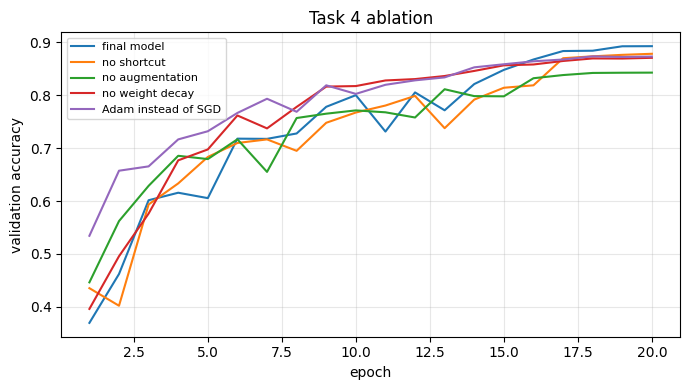

In [25]:
ABLATIONS = {
    "final model":         {},
    "no shortcut":         dict(residual=False),
    "no augmentation":     dict(augment="none"),
    "no weight decay":     dict(weight_decay=0.0),
    "Adam instead of SGD": dict(optimizer="adam", lr=1e-3, weight_decay=1e-4),
}

results_4, models_4 = {}, {}
for name, change in ABLATIONS.items():
    print(f"--- {name} ---")
    cfg = dict(BASE_CONFIG, **change)
    models_4[name], results_4[name], n_params = run_experiment(cfg)

print(f"\n{'setting':<22} {'final val acc':>14} {'change vs final':>16}")
base_acc = results_4["final model"]["val_acc"][-1]
for name, h in results_4.items():
    acc = h["val_acc"][-1]
    print(f"{name:<22} {acc:>14.4f} {acc - base_acc:>+16.4f}")

plt.figure(figsize=(7, 4))
for name, h in results_4.items():
    plt.plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], label=name)
plt.xlabel("epoch"); plt.ylabel("validation accuracy")
plt.title("Task 4 ablation"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Ablation discussion.**

The final model reaches 89.3% validation accuracy with 420,670 parameters in 20 epochs.

* **No shortcut:** -1.4 points (87.8%). At depth 20 the plain network still trains reasonably well (as in 3(b)), so the gap is small but still present.
* **No augmentation:** -5.0 points (84.3%), the biggest drop. Without augmentation the model starts to overfit within 20 epochs, even with 45k images; its validation accuracy flattens out after about epoch 17.
* **No weight decay:** -2.2 points (87.1%).
* **Adam instead of SGD:** -2.0 points (87.3%). Adam learns faster at the start (it leads until about epoch 15), but SGD with momentum and a cosine schedule ends higher. This agrees with Task 2(c), where Adam's advantage was also mainly fast early progress and only about 1 point at the end. Here SGD uses a well-tuned recipe, while Adam was not tuned and uses L2 weight decay, which works less well with Adam than with SGD.

The most important design choice was data augmentation.

### Final test evaluation


The test set is loaded here for the first and only time. It is normalized with the **training** mean and standard deviation from Task 1, and the final model (chosen using the validation set only) is evaluated once. Do not change anything after seeing this number.

In [26]:
test_set = torchvision.datasets.CIFAR10(root="./data", train=False, download=True)
X_test = torch.tensor(test_set.data).permute(0, 3, 1, 2).float() / 255.0
X_test = ((X_test - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)).to(device)
y_test = torch.tensor(test_set.targets).to(device)

final_model = models_4["final model"]
test_loss, test_acc = evaluate_model(final_model, X_test, y_test)
print(f"Final model: {count_params(final_model):,} parameters, 20 epochs")
print(f"Validation accuracy: {results_4['final model']['val_acc'][-1]:.4f}")
print(f"TEST accuracy:       {test_acc:.4f}")

Final model: 420,670 parameters, 20 epochs
Validation accuracy: 0.8928
TEST accuracy:       0.8903


**Result.** <!-- Fill in. -->
The final model reaches a test accuracy of 89%, close to its validation accuracy of 89.3%. A small difference is expected because the model was tuned on the validation set.